# CreditRisk+ y el ajuste por granularidad

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 03 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- describir el modelo CreditRisk+, en que los incumplimientos son conteos de Poisson gobernados por un factor sectorial Gamma, y decir cómo se calcula su distribución de pérdidas sin simulación;
- correr la recursión estable en la cartera ilustrativa, comprobar su primera probabilidad contra una forma cerrada, y leer VaR y déficit esperado de la distribución exacta;
- mostrar en una cartera de estrés construida por qué la recursión original de tipo Panjer se conserva solo como comparación;
- enunciar el ajuste por granularidad de Gordy y Lutkebohmert, reproducir su vector de prueba, y calcularlo para la cartera a partir del capital IRB de cada grupo;
- leer la brecha entre la fórmula infinitamente granular y una cartera finita y concentrada, y decir dónde el ajuste la sobrestima;
- probar la recursión contra una muestra de Monte Carlo del mismo modelo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate, stats

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos de los cinco archivos por tipo de préstamo del caso C10 (propietario: este repositorio; las tasas de pérdida detrás de los ajustes vienen de la tabla `chgallsa` de la Reserva Federal, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, dominio público, clase de licencia `mirror-allowed`):

- `data/derived/C10/commercial-industrial.json`: la cartera ilustrativa de 1.120 nombres (`outputs.portfolio`), el peldaño CreditRisk+ versionado (`outputs.rungs`, con sus parámetros y diagnósticos), el bloque de granularidad (`outputs.granularity`) y la fila de prueba de la recursión contra Monte Carlo (`tests`);
- `data/derived/C10/credit-cards.json`: los mismos bloques para la cartera de tarjetas de crédito, usado en el Paso 5 porque su tabla de granularidad trae la respuesta exacta de CreditRisk+ que le falta al archivo comercial.

La cartera es construida y está etiquetada `illustrative`, nunca la de un banco. La celda siguiente carga ambos archivos e imprime lo que usó el peldaño CreditRisk+ versionado.

In [2]:
# Cargar los dos artefactos e imprimir lo que usó el peldaño CreditRisk+ versionado
doc = json.loads((ROOT / "data" / "derived" / "C10" / "commercial-industrial.json").read_text(encoding="utf-8"))
cards = json.loads((ROOT / "data" / "derived" / "C10" / "credit-cards.json").read_text(encoding="utf-8"))
out = doc["outputs"]
book = out["portfolio"]
groups = book["groups"]
pd_hat = out["fit"]["maximum_likelihood"]["pd"]["estimate"]
rho_hat = out["fit"]["maximum_likelihood"]["rho"]["estimate"]
rungs = {r["id"]: r for r in out["rungs"]}
crp = rungs["c4-creditrisk-plus"]

print("calculado con riskvalidation", doc["provenance"]["riskvalidation_version"])
print("cartera:", si_no(book["label"]), "|", book["n_names"], "nombres |", f"{book['total_ead']:,.0f}", book["currency"])
print("parámetros de CreditRisk+:", [(p["name"], p["value"]) for p in crp["parameters"]])
print("diagnósticos de CreditRisk+:", [(d["name"], d["value"]) for d in crp["diagnostics"]])

calculado con riskvalidation 0.7.0
cartera: ilustrativa | 1120 nombres | 100,000,000 USD
parámetros de CreditRisk+: [('sigma2', 0.552065603), ('loss_unit', 1000.0)]
diagnósticos de CreditRisk+: [('n_max', 12728.0), ('tail_mass_left_out', -1.54321e-13), ('expected_loss', 409720.505), ('unit_rounding', 0.0)]


## Método

### Paso 1: el modelo CreditRisk+

CreditRisk+ es la contraparte actuarial de los modelos de cópula. Las exposiciones son múltiplos enteros $\nu_i$ de una **unidad de pérdida** (aquí 1.000 USD de pérdida, es decir, exposición por LGD). El número de incumplimientos del nombre $i$ es Poisson con una intensidad que depende de un **factor sectorial** $S$ con distribución Gamma de media 1 y varianza $\sigma^2$, y la pérdida de la cartera en unidades es $X=\sum_i \nu_i Y_i$. Con un sector y sin peso idiosincrático, la intensidad del nombre $i$ es $p_i S$. La función generadora de probabilidad de la pérdida, el objeto desde el cual se calcula la distribución, es (Haaf, Reiss y Schoenmakers, 2004, https://doi.org/10.21314/jor.2004.097):

$$G(z) = \exp\!\left(-\frac{1}{\sigma^2}\ln\!\left[1-\sigma^2\sum_i p_i\,(z^{\nu_i}-1)\right]\right)$$

El modelo tiene límites que recordar: solo modo de incumplimiento, recuperaciones determinísticas en el modelo básico, y una aproximación de Poisson que puede dar varios incumplimientos de un mismo deudor cuando una PD es grande. La varianza Gamma es un parámetro que el caso fija por igualación de momentos: $\sigma^2$ es la varianza de la tasa de incumplimiento de Vasicek del cuaderno 01 sobre la PD al cuadrado, $\sigma^2=(E[p(Z)^2]-\mathrm{PD}^2)/\mathrm{PD}^2$. Es una elección de calibración, no una medida de riesgo. La celda siguiente construye el insumo del motor a partir de los grupos, con el $\sigma^2$ versionado, y recalcula $\sigma^2$ por integración numérica de la PD condicional del cuaderno 01 para comprobar el valor versionado.

In [3]:
# Construir el insumo de CreditRisk+ a partir de los grupos y comprobar el sigma cuadrado versionado por integración numérica
from riskvalidation.engines.vasicek import conditional_pd
from riskvalidation.portfolio import creditrisk_plus as cr

loss_unit = next(p["value"] for p in crp["parameters"] if p["name"] == "loss_unit")
sigma2 = next(p["value"] for p in crp["parameters"] if p["name"] == "sigma2")
lgd = book["lgd_mean"]

ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in groups])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in groups])
units = np.rint(ead * lgd / loss_unit).astype(int)
inp = cr.CreditRiskPlusInput(nu=units, pd=pd_names, w0=np.zeros(ead.size), weights=np.ones((ead.size, 1)),
                             sigma2=np.array([sigma2]), loss_unit=loss_unit, currency=book["currency"])
print("nombres:", ead.size, "| bandas de exposición (unidades de pérdida):", sorted(set(units.tolist())), "| unidades totales:", int(units.sum()))
print("redondeo de exposición x LGD a unidades enteras:", float(np.abs(units * loss_unit - ead * lgd).max()))
print("número esperado de incumplimientos:", round(float(pd_names.sum()), 4))

second_moment, _ = integrate.quad(lambda z: float(conditional_pd(pd_hat, rho_hat, z)) ** 2 * stats.norm.pdf(z), -12, 12, epsabs=1e-16, epsrel=1e-12, limit=200)
print("sigma^2 versionado:", sigma2, "| por integración:", round((second_moment - pd_hat ** 2) / pd_hat ** 2, 9))

nombres: 1120 | bandas de exposición (unidades de pérdida): [9, 180, 900] | unidades totales: 45000
redondeo de exposición x LGD a unidades enteras: 0.0
número esperado de incumplimientos: 16.2877
sigma^2 versionado: 0.552065603 | por integración: 0.552065603


### Paso 2: la recursión estable y su distribución exacta

Tomando logaritmos de la función generadora y expandiendo en potencias de $z$ se obtiene una recursión para las probabilidades $p_n=P(X=n)$. Si $\ln G(z)=\sum_{j\ge 0} a_j z^j$, entonces $p_0=e^{a_0}$ y $n\,p_n=\sum_{j=1}^{n} j\,a_j\,p_{n-j}$. En la forma estable de Haaf, Reiss y Schoenmakers (2004) todo coeficiente $a_j$ con $j\ge1$ es no negativo, así que no hay restas de términos de signo opuesto y ninguna probabilidad puede salir negativa. `pmf_stable` del motor calcula $p_0,\dots,p_{n_{\max}}$ y deja fuera la masa de la cola. Una forma cerrada la comprueba: con un sector, $P(X=0)=G(0)=(1+\sigma^2\mu)^{-1/\sigma^2}$ donde $\mu=\sum_i p_i$ es el número esperado de incumplimientos. `measures_from_pmf` lee entonces VaR y déficit esperado en la grilla de unidades con el estimador discreto de Acerbi y Tasche. La celda siguiente corre la recursión hasta el largo de grilla que usó el pipeline, comprueba $p_0$ y la masa faltante, y compara las medidas con el peldaño versionado.

In [4]:
# Correr la recursión estable, comprobar P(X = 0) contra su forma cerrada y comparar VaR y ES con el peldaño versionado
n_max = int(next(d["value"] for d in crp["diagnostics"] if d["name"] == "n_max"))
pmf = cr.pmf_stable(inp, n_max)
mu = float(pd_names.sum())
print("n_max:", n_max, "| masa en la grilla:", round(float(pmf.sum()), 12), "| entradas negativas:", int((pmf < 0).sum()))
print("P(X = 0) recursión:", f"{pmf[0]:.12e}", "| forma cerrada:", f"{(1 + sigma2 * mu) ** (-1 / sigma2):.12e}")

measures = cr.measures_from_pmf(pmf, loss_unit, (0.99, 0.999))
for m, c in zip(measures, crp["measures"]):
    print(f"q = {m.level}: EL {m.el:,.0f} | VaR {m.var:,.0f} | ES {m.es:,.0f} | capital {m.ec:,.0f}   versionado: VaR {c['var']:,.0f} | ES {c['es']:,.0f}")

n_max: 12728 | masa en la grilla: 1.0 | entradas negativas: 0
P(X = 0) recursión: 1.546187529854e-02 | forma cerrada: 1.546187529854e-02
q = 0.99: EL 409,721 | VaR 2,079,000 | ES 2,514,778 | capital 1,669,279   versionado: VaR 2,079,000 | ES 2,514,778
q = 0.999: EL 409,721 | VaR 3,078,000 | ES 3,506,025 | capital 2,668,279   versionado: VaR 3,078,000 | ES 3,506,025


La recursión da toda la distribución de una vez. La celda siguiente dibuja su probabilidad de excedencia, la probabilidad de una pérdida sobre cada nivel, junto a dos referencias versionadas: la cópula gaussiana de un factor (un Monte Carlo de un millón de escenarios) y el límite de la cartera grande. CreditRisk+ con el $\sigma^2$ igualado por momentos y la cópula gaussiana describen la misma cartera con supuestos distintos, y las dos curvas son cercanas en el cuerpo y se separan en la cola lejana.

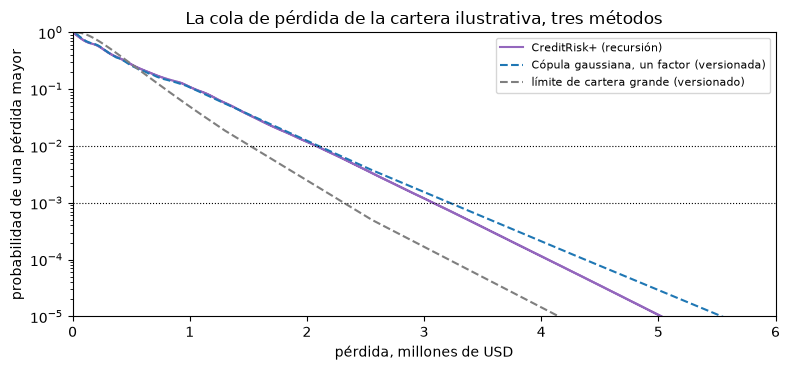

In [5]:
# Dibujar la probabilidad de excedencia de CreditRisk+ frente a la cópula gaussiana versionada y el límite de la cartera grande
fig, ax = plt.subplots(figsize=(8, 3.8))
loss_grid = np.arange(pmf.size) * loss_unit
ax.plot(loss_grid / 1e6, 1 - np.cumsum(pmf), label="CreditRisk+ (recursión)", color="tab:purple")
for rid, label, color in (("c2-gaussian-1f", "Cópula gaussiana, un factor (versionada)", "tab:blue"), ("c1-lhp", "límite de cartera grande (versionado)", "tab:gray")):
    curve = rungs[rid]["distribution"]
    ax.plot(np.array(curve["loss"]) / 1e6, 1 - np.array(curve["cdf"]), label=label, color=color, linestyle="--")
for q in (0.99, 0.999):
    ax.axhline(1 - q, color="black", linestyle=":", linewidth=0.8)
ax.set_yscale("log")
ax.set_ylim(1e-5, 1)
ax.set_xlim(0, 6)
ax.set_xlabel("pérdida, millones de USD")
ax.set_ylabel("probabilidad de una pérdida mayor")
ax.set_title("La cola de pérdida de la cartera ilustrativa, tres métodos")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Paso 3: por qué la recursión original se conserva solo como comparación

La recursión del documento original de CreditRisk+ despeja los denominadores de la función generadora multiplicándolos. Eso resta términos de signo opuesto, y el error de redondeo puede dar entonces probabilidades negativas (la inestabilidad señalada por Haaf, Reiss y Schoenmakers, 2004). `pmf_panjer` del motor tiene la misma firma que `pmf_stable` y se conserva solo para mostrar esto; no recorta nada. En la cartera de este caso, con un sector, las dos coinciden hasta el redondeo. La celda siguiente las compara ahí y luego en una **cartera de estrés construida**: 30.000 nombres en 5 bandas de exposición, 8 sectores con varianzas Gamma de 0,02 a 12, y unos 1.800 incumplimientos esperados, sorteada con un generador con semilla. La cartera de estrés es sintética, construida aquí para mostrar la falla, y no es un caso del producto.

In [6]:
# Comparar las recursiones estable y de Panjer en la cartera del caso y en una cartera de estrés construida
panjer = cr.pmf_panjer(inp, n_max)
print("cartera del caso: mayor diferencia", f"{np.abs(panjer - pmf).max():.1e}", "| entradas negativas de Panjer:", int((panjer < 0).sum()))

rng = np.random.default_rng(3)
n_stress, n_sectors = 30_000, 8
stress_units = rng.integers(1, 6, size=n_stress)
stress_pd = rng.uniform(0.03, 0.09, size=n_stress)
stress_w = rng.dirichlet(np.ones(n_sectors + 1), size=n_stress)
stress = cr.CreditRiskPlusInput(
    nu=stress_units, pd=stress_pd, w0=stress_w[:, 0], weights=stress_w[:, 1:],
    sigma2=np.array([0.02, 0.2, 0.8, 1.5, 3.0, 6.0, 9.0, 12.0]), loss_unit=1.0, currency="USD")
stress_grid = 6000
stable_s = cr.pmf_stable(stress, stress_grid)
panjer_s = cr.pmf_panjer(stress, stress_grid)
outside = lambda p: int(((p < 0) | (p > 1)).sum())
print("cartera de estrés:", n_stress, "nombres,", n_sectors, "sectores, incumplimientos esperados", round(float(stress.pd.sum())))
print("estable: entradas fuera de [0, 1]", outside(stable_s), "| entrada más pequeña", f"{stable_s.min():.2e}", "| suma de las probabilidades", round(float(stable_s.sum()), 3))
print("Panjer: entradas fuera de [0, 1]", si_no(outside(panjer_s) > 0), "| entradas negativas", si_no(int((panjer_s < 0).sum()) > 0), "| suma de las probabilidades dentro de [0, 1]", si_no(0 <= panjer_s.sum() <= 1))

cartera del caso: mayor diferencia 1.6e-17 | entradas negativas de Panjer: 0
cartera de estrés: 30000 nombres, 8 sectores, incumplimientos esperados 1802
estable: entradas fuera de [0, 1] 0 | entrada más pequeña 1.58e-137 | suma de las probabilidades 0.721
Panjer: entradas fuera de [0, 1] sí | entradas negativas sí | suma de las probabilidades dentro de [0, 1] no


### Paso 4: el ajuste por granularidad

La fórmula de la cartera grande supone nombres tan pequeños que el riesgo idiosincrático desaparece. Una cartera concentrada conserva algo de él, y el capital debe ser mayor. Gordy y Lutkebohmert (2013, https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf) dan un ajuste simplificado, una parte de la exposición, construido sobre el modelo CreditRisk+ de un factor con un factor Gamma de media 1 y varianza $1/\xi$:

$$\mathrm{GA}=\frac{1}{2K^*}\sum_i s_i^2\,C_i\,\big(\delta\,(K_i+R_i)-K_i\big),\qquad \delta=(\alpha_q-1)\left(\xi+\frac{1-\xi}{\alpha_q}\right)$$

donde $s_i$ es la participación de la exposición, $K_i$ el capital del nombre $i$ por unidad de exposición, $K^*=\sum_i s_iK_i$, $R_i=E[\mathrm{LGD}_i]\,\mathrm{PD}_i$ la reserva, $C_i=(V[\mathrm{LGD}_i]+E[\mathrm{LGD}_i]^2)/E[\mathrm{LGD}_i]$, $V[\mathrm{LGD}_i]=\gamma\,E[\mathrm{LGD}_i](1-E[\mathrm{LGD}_i])$ y $\alpha_q$ el cuantil $q$ del factor Gamma (ecuaciones 11, 15, 16 y 17 del artículo). El artículo da un vector de prueba: $\xi=0{,}25$ y $q=0{,}999$ dan $\delta=4{,}83$. `delta` y `gamma_quantile` del motor lo calculan; la celda siguiente reproduce el vector y muestra cómo se mueve $\delta$ con $\xi$ y $q$.

In [7]:
# Reproducir el vector de prueba del artículo delta = 4.83 y mostrar delta para otras precisiones y niveles
from riskvalidation.portfolio import granularity as gr

xi_ref = out["granularity"]["xi"]
print("xi =", xi_ref, "| q = 0.999 | alpha_q =", round(gr.gamma_quantile(xi_ref, 0.999), 4), "| delta =", round(gr.delta(xi_ref, 0.999), 4), "| artículo:", out["granularity"]["delta_reference"], "| versionado:", out["granularity"]["levels"][1]["delta"])
print(f"{'xi':>6s} {'q = 0.99':>10s} {'q = 0.999':>10s} {'q = 0.9995':>11s}")
for xi in (0.25, 0.5, 1.0, 2.0):
    print(f"{xi:6.2f} {gr.delta(xi, 0.99):10.4f} {gr.delta(xi, 0.999):10.4f} {gr.delta(xi, 0.9995):11.4f}")

xi = 0.25 | q = 0.999 | alpha_q = 17.5058 | delta = 4.8336 | artículo: 4.83 | versionado: 4.83360126
    xi   q = 0.99  q = 0.999  q = 0.9995
  0.25     2.8568     4.8336      5.4482
  0.50     3.2421     5.3676      6.0166
  1.00     3.6052     5.9078      6.6009
  2.00     3.9396     6.4500      7.1987


Ahora el ajuste para la cartera. El capital $K_i$ de cada nombre es el capital IRB del grupo del nombre con su propia PD, una LGD de 45% y un vencimiento de 2,5 años (Basel Framework CRE31, https://www.bis.org/basel_framework/chapter/CRE/31.htm), como prescribe el algoritmo regulatorio del artículo. `capital_requirement` del motor lo devuelve y `granularity_adjustment` aplica la fórmula, con $\xi=0{,}25$ y $\gamma=0{,}25$ del artículo leídos del artefacto. El ajuste es una parte de la exposición; sumarlo al VaR de la cartera grande da el capital de la cartera con su concentración.

In [8]:
# Calcular el ajuste por granularidad de la cartera a partir del capital IRB de cada grupo y compararlo con el bloque versionado
from riskvalidation.portfolio.portfolio import lhp_measures
from riskvalidation.regulatory.irb import capital_requirement

gran = out["granularity"]
k_group = {g["id"]: float(capital_requirement("corporate", g["pd"], lgd, regime="basel3", maturity=2.5).k) for g in groups}
k_names = np.concatenate([np.full(g["n_names"], k_group[g["id"]]) for g in groups])
share = ead / ead.sum()
print("K por grupo (capital IRB por unidad de exposición):", {k: round(v, 5) for k, v in k_group.items()})

for level, committed in zip((0.99, 0.999), gran["levels"]):
    res = gr.granularity_adjustment(share, k_names, pd_names, np.full(ead.size, lgd), gran["gamma"], gran["xi"], level)
    var_lhp = lhp_measures(book["total_ead"], lgd, pd_hat, rho_hat, (level,))[0].var
    print(f"q = {level}: delta {res.delta:.4f} | K* {res.k_star:.6f} | GA {res.ga:.8f} (versionado {committed['ga']:.8f}) | en dinero {res.ga * book['total_ead']:,.0f}")
    print(f"        VaR de la cartera grande {var_lhp:,.0f} | con el ajuste {var_lhp + res.ga * book['total_ead']:,.0f} | GA sobre el VaR de la cartera grande {res.ga * book['total_ead'] / var_lhp:.3f}")

K por grupo (capital IRB por unidad de exposición): {'g-large': 0.05598, 'g-mid': 0.07416, 'g-small': 0.08477}
q = 0.99: delta 2.8568 | K* 0.069012 | GA 0.00481771 (versionado 0.00481771) | en dinero 481,771
        VaR de la cartera grande 1,500,956 | con el ajuste 1,982,727 | GA sobre el VaR de la cartera grande 0.321
q = 0.999: delta 4.8336 | K* 0.069012 | GA 0.00982976 (versionado 0.00982976) | en dinero 982,976
        VaR de la cartera grande 2,298,833 | con el ajuste 3,281,809 | GA sobre el VaR de la cartera grande 0.428


### Paso 5: el ajuste frente a la respuesta exacta de una cartera finita

El ajuste es una aproximación asintótica, proporcional al HHI de las participaciones de exposición, así que para $n$ nombres idénticos $\mathrm{GA}\times n$ es constante. ¿Qué tan bueno es para una cartera pequeña? Para $n$ nombres idénticos el modelo CreditRisk+ de un factor del artículo se puede resolver exactamente con la recursión: el peso de los nombres sobre el factor es $\omega=K/(E[\mathrm{LGD}]\,\mathrm{PD}\,(\alpha_q-1))$ (ecuación 13 del artículo, despejada para $\omega$), la varianza Gamma es $1/\xi$, y el ajuste exacto es la diferencia entre la participación exacta del VaR de la cartera, $E[\mathrm{LGD}]\,\mathrm{VaR}_{\text{unidades}}/n$, y la infinitamente granular, $E[\mathrm{LGD}]\,\mathrm{PD}+K$. La condición es $0<\omega\le1$. Para la cartera comercial $\omega$ es mayor que 1, así que la recursión no se corrió y el archivo versionado no tiene respuesta exacta; la cartera de tarjetas la cumple. La celda siguiente calcula, para tarjetas, el ajuste y la brecha exacta para $n=10$, $100$ y $1.000$ nombres, y el $\omega$ comercial.

In [9]:
# Para n nombres idénticos comparar el ajuste con la brecha exacta de CreditRisk+ (tarjetas), y mostrar el omega comercial
def exact_gap(pd_i, k_i, n, q=0.999, xi=0.25, lgd_i=0.45):
    """El peso omega sobre el factor y el ajuste exacto de n nombres idénticos por la recursión"""
    omega_i = k_i / (lgd_i * pd_i * (gr.gamma_quantile(xi, q) - 1.0))
    if not 0.0 < omega_i <= 1.0:
        return omega_i, None
    names = cr.CreditRiskPlusInput(nu=np.ones(n, dtype=np.int64), pd=np.full(n, pd_i), w0=np.full(n, 1.0 - omega_i), weights=np.full((n, 1), omega_i),
                                   sigma2=np.array([1.0 / xi]), loss_unit=1.0, currency="USD")
    grid = max(40, 4 * n)
    while True:
        p = cr.pmf_stable(names, grid)
        if p.sum() >= q + 1e-6 or grid >= 20 * n:
            break
        grid *= 2
    var_units = cr.measures_from_pmf(p, 1.0, (q,))[0].var
    return omega_i, max(lgd_i * var_units / n - (lgd_i * pd_i + k_i), 0.0)

c_out = cards["outputs"]
pd_cards = c_out["fit"]["maximum_likelihood"]["pd"]["estimate"]
k_cards = float(capital_requirement(c_out["irb_reference"]["asset_class"], pd_cards, lgd, regime="basel3").k)
committed_rows = {r["n_names"]: r for r in c_out["granularity"]["by_n_names"]}

print("tarjetas: PD", round(pd_cards, 5), "| K", round(k_cards, 5))
print(f"{'nombres':>7s} {'GA (fórmula)':>14s} {'GA x n':>9s} {'brecha exacta':>14s} {'exacta versionada':>16s} {'fórmula / exacta':>16s}")
for n_names in (10, 100, 1000):
    formula = gr.granularity_adjustment(np.full(n_names, 1 / n_names), np.full(n_names, k_cards), np.full(n_names, pd_cards), np.full(n_names, lgd), gran["gamma"], gran["xi"], 0.999).ga
    omega_c, truth = exact_gap(pd_cards, k_cards, n_names)
    print(f"{n_names:7d} {formula:14.6f} {formula * n_names:9.4f} {truth:14.6f} {committed_rows[n_names]['truth_ga']:16.6f} {formula / truth:16.2f}")
k_commercial = float(capital_requirement("corporate", pd_hat, lgd, regime="basel3", maturity=2.5).k)
print("comercial: omega implícito en K:", round(exact_gap(pd_hat, k_commercial, 100)[0], 3), "(fuera de (0, 1]: sin respuesta exacta)")

tarjetas: PD 0.04228 | K 0.03917
nombres   GA (fórmula)    GA x n  brecha exacta exacta versionada fórmula / exacta
     10       0.181580    1.8158       0.121804         0.121804             1.49
    100       0.018158    1.8158       0.013804         0.013804             1.32
   1000       0.001816    1.8158       0.001204         0.001204             1.51
comercial: omega implícito en K: 1.055 (fuera de (0, 1]: sin respuesta exacta)


### Paso 6: la recursión frente a un Monte Carlo del mismo modelo

La distribución exacta debe coincidir con una simulación del mismo modelo Poisson-Gamma. `crp_recursion_vs_mc` del motor mide la distancia de Kolmogorov entre la función de distribución de la recursión y la de una muestra, con la ley asintótica de Kolmogorov para su valor p (conservadora para una distribución discreta, la definición del contrato); es roja sea cual sea el valor p si alguna probabilidad es negativa. El comparador es una simulación simple escrita aquí desde la definición del modelo, una comprobación independiente y no un segundo motor: sortear el factor Gamma y, para cada grupo, sortear un conteo de Poisson con intensidad (nombres por PD por factor) y multiplicarlo por las unidades de pérdida del grupo. La celda siguiente sortea 100.000 escenarios con la semilla del pipeline y compara con la fila versionada de 400.000.

In [10]:
# Simular el modelo Poisson-Gamma y probar la recursión contra la muestra, y luego comparar con la fila versionada
from riskvalidation.validation.portfolio import crp_recursion_vs_mc

rng_crp = np.random.default_rng(np.random.PCG64(4006))
n_mc = 100_000
factor = rng_crp.gamma(shape=1.0 / sigma2, scale=sigma2, size=n_mc)
sample_units = np.zeros(n_mc, dtype=np.int64)
first = 0
for g in groups:
    sample_units += int(units[first]) * rng_crp.poisson(g["n_names"] * g["pd"] * factor)
    first += g["n_names"]

verdict = crp_recursion_vs_mc(pmf, sample_units, model_id="m-creditrisk-plus")
row = next(t for t in doc["tests"] if t["test_id"] == "portfolio.crp_recursion_vs_mc")
print("escenarios:", n_mc, "| distancia de Kolmogorov:", round(verdict.statistic, 5), "| p-value:", round(verdict.p_value, 4), "|", si_no(verdict.light.value), "| entradas negativas:", verdict.extras["negative_entries"])
print("fila versionada:", row["n"], "escenarios | D", round(row["statistic"], 5), "| p-value", round(row["p_value"], 4), "|", si_no(row["light"]))

escenarios: 100000 | distancia de Kolmogorov: 0.00398 | p-value: 0.0843 | verde | entradas negativas: 0
fila versionada: 400000 escenarios | D 0.00126 | p-value 0.5535 | verde


La última celda pone los métodos lado a lado. Para la misma cartera y la misma PD y correlación ajustadas, lista el VaR al 99,9% versionado de cada peldaño que calcula uno: el límite de la cartera grande, CreditRisk+, la cópula gaussiana por Monte Carlo y por muestreo por importancia (cuaderno 05), y el límite de la cartera grande más el ajuste por granularidad. La brecha entre el primero y los demás es el precio de una cartera finita y concentrada.

In [11]:
# Listar el VaR al 99.9% versionado de cada peldaño que calcula uno y su razón con el límite de la cartera grande
base = rungs["c1-lhp"]["measures"][1]["var"]
print(f"{'peldaño':22s} {'VaR 99.9%':>12s} {'razón con el límite':>22s}")
for rid in ("c1-lhp", "c4-creditrisk-plus", "c2-gaussian-1f", "c6-is-gaussian", "c5-granularity"):
    var999 = rungs[rid]["measures"][1]["var"]
    print(f"{rid:22s} {var999:12,.0f} {var999 / base:22.3f}")
print("ajuste por granularidad al 99.9% en dinero:", f"{gran['levels'][1]['ga_money']:,.0f}", "| impact.ga_999_share:", round(doc["impact"]["ga_999_share"]["value"], 5))

peldaño                   VaR 99.9%    razón con el límite
c1-lhp                    2,298,834                  1.000
c4-creditrisk-plus        3,078,000                  1.339
c2-gaussian-1f            3,177,000                  1.382
c6-is-gaussian            3,204,000                  1.394
c5-granularity            3,281,809                  1.428
ajuste por granularidad al 99.9% en dinero: 982,976 | impact.ga_999_share: 0.00983


## Resultados

- **La recursión da toda la distribución de pérdidas de forma exacta, y su ancla se cumple.** Para la cartera de 1.120 nombres la recursión estable pone masa 1,0 en una grilla de 12.728 unidades sin entradas negativas, y su primera probabilidad, 1,546187529854e-02, es igual a la forma cerrada $(1+\sigma^2\mu)^{-1/\sigma^2}$ en todos los dígitos impresos. El VaR al 99% y al 99,9% es 2.079.000 y 3.078.000 USD, los déficits esperados 2.514.778 y 3.506.025 USD, y el capital al 99,9% 2.668.279 USD, iguales al peldaño versionado (calculado con el motor 0.7.0, instalado el 0.8.1). El $\sigma^2$ igualado por momentos de 0,552065603 también se reproduce por integración numérica.
- **La recursión original de Panjer es inestable donde importa.** En la cartera del caso coincide con la estable hasta 1,6e-17 y no tiene entradas negativas, así que el caso no muestra el problema. En la cartera de estrés construida (30.000 nombres, 8 sectores) devuelve probabilidades negativas y entradas fuera de [0, 1], y sus probabilidades no suman un valor en [0, 1], mientras que la recursión estable no tiene entradas fuera de [0, 1] (su suma, 0,721, es menor que 1 solo porque la grilla de 6.000 unidades corta la cola, que el motor deja fuera y nunca vuelve a sumar). Por eso el motor entrega la forma de Panjer solo como comparación.
- **El ajuste por granularidad reproduce el artículo y suma entre 32% y 43% al VaR de la cartera grande.** El vector de prueba se cumple: $\delta=4{,}8336$ con $\xi=0{,}25$ y $q=0{,}999$ frente al 4,83 impreso en el artículo. Con el capital IRB de cada grupo (0,05598, 0,07416 y 0,08477 por unidad de exposición, que dan $K^*=0{,}069012$) el ajuste es 0,00481771 de la exposición al 99% y 0,00982976 al 99,9%, iguales a los valores versionados, es decir 481.771 y 982.976 USD. Al 99,9% es 42,8% del VaR de la cartera grande de 2.298.833 USD, y el VaR de la cartera grande con el ajuste es 3.281.809 USD.
- **La cartera finita necesita más capital que el que dice el límite, con cualquier método.** Al 99,9%, respecto del límite de la cartera grande, CreditRisk+ es 1,339 veces, la cópula gaussiana por Monte Carlo 1,382, por muestreo por importancia 1,394, y el límite más el ajuste 1,428. La cartera tiene 104 nombres efectivos. Los cuatro no son comparables uno a uno: CreditRisk+ y el ajuste descansan en un factor Gamma (el ajuste en el $\xi=0{,}25$ del artículo y el capital IRB), la cópula gaussiana en un factor normal.
- **Frente a la respuesta exacta, el ajuste sobrestima la brecha.** Para nombres idénticos de tarjetas de crédito la fórmula por $n$ es constante, 1,8158, como dice la teoría, y la brecha exacta de CreditRisk+ es 0,121804, 0,013804 y 0,001204 con 10, 100 y 1.000 nombres, reproduciendo los valores versionados. La fórmula es 1,49, 1,32 y 1,51 veces la brecha exacta. Para la cartera comercial el peso implícito sobre el factor es 1,055, fuera de (0, 1], así que no hay respuesta exacta y el archivo versionado registra el motivo en lugar de un número.
- **La recursión concuerda con una simulación de su propio modelo.** Con 100.000 escenarios la distancia de Kolmogorov es 0,00398 (p = 0,084, verde) y con los 400.000 versionados es 0,00126 (p = 0,55, verde); ninguna probabilidad es negativa. La prueba es sobre la forma de la distribución, no sobre un cuantil, y su valor p asintótico es conservador para una distribución discreta.

Lo que este cuaderno no muestra: cómo se reparte el capital entre los grupos (cuaderno 05), si el ajuste es conservador para la cartera comercial (no existe respuesta exacta para ella), ni qué modelo es el correcto. CreditRisk+ y las cópulas son supuestos distintos sobre la misma cartera.

## Resumen

- CreditRisk+ modela los incumplimientos como conteos de Poisson gobernados por un factor Gamma; su distribución de pérdidas sale de una recursión sobre la función generadora, sin simulación, y `pmf_stable` es exacta y no negativa.
- La recursión original de Panjer resta términos de signo opuesto y falla en una cartera grande de varios sectores; el motor la conserva solo como comparación.
- El ajuste por granularidad (`granularity_adjustment`, `delta`) reproduce el vector de prueba del artículo y suma 42,8% al VaR de la cartera grande al 99,9%.
- Frente a la brecha exacta de CreditRisk+ de nombres idénticos, la fórmula sobrestima entre 32% y 51% en la cartera de tarjetas, y una cartera cuyo peso implícito sobre el factor queda fuera de (0, 1] no tiene respuesta exacta.
- `crp_recursion_vs_mc` prueba la recursión contra una simulación de su propio modelo.

**Qué probar a continuación.** Cambia el número de nombres del Paso 5 a 20 y 500 para tarjetas y compara la fórmula con la brecha exacta. Luego abre el cuaderno 05, donde el capital de la cartera se reparte entre sus grupos.

## Referencias

- Haaf, H., Reiss, O. y Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- Gordy, M. B. y Lutkebohmert, E. (2013), Granularity adjustment for regulatory capital assessment, International Journal of Central Banking 9(3):33-48. https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- BCBS, Basel Framework, CRE31: IRB approach, risk weight functions for corporate, bank, sovereign and retail exposures. https://www.bis.org/basel_framework/chapter/CRE/31.htm
- Acerbi, C. y Tasche, D. (2002), On the coherence of expected shortfall, Journal of Banking and Finance 26(7):1487-1503. https://doi.org/10.1016/S0378-4266(02)00283-2
- Federal Reserve charge-off table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm (public domain; licence class mirror-allowed).
- Credit Suisse First Boston (1997), CreditRisk+: A Credit Risk Management Framework, the original model document: not accessed by the persisted research (UNVERIFIED primary); the model statement is verified from Haaf, Reiss and Schoenmakers (2004).
- Persisted research dossier 04 of this product (credit-risk models, state of the art), sections H.4 and H.5 (CreditRisk+ and the granularity adjustment).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.